# 4 · What did the synthetic validation establish?

All numbers below are read from saved benchmark artifacts. Missing artifacts produce
an explanatory message, not invented results. The unit of replication is an independent
simulated movie; uncertainty in coverage and detection rates is computed across movies.

The prespecified decision is posterior probability greater than 0.95 for an effect
beyond a factor of 1.2 in the hypothesized direction: lower active amplitude,
shorter persistence, or greater jitter. A null false-positive rate and an alternative
detection rate are different quantities. Absence of detection is not evidence of equivalence.

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
from io import BytesIO
import json
import os
import sys

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'pyproject.toml').is_file()
             and (p / 'src' / 'motility_inference').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Launch this notebook from the project or its notebooks directory.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
RESULTS = ROOT / 'results' / 'synthetic_v1'
RUN_TRAINING = False  # Large simulation banks and MCMC are never launched by default.
(ROOT / '.cache').mkdir(exist_ok=True)
os.environ.setdefault('XDG_CACHE_HOME', str(ROOT / '.cache'))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache' / 'matplotlib'))

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
from motility_inference.simulator import SimConfig, simulate, load_dataset, proximity
from motility_inference.priors import PARAMETER_NAMES, PRIOR_LOW, PRIOR_HIGH, scenario_theta

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})

def show(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format='png', dpi=130, bbox_inches='tight')
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

def read_json(name):
    path = RESULTS / name
    if not path.is_file():
        return None
    try:
        return json.loads(path.read_text())
    except json.JSONDecodeError:
        print(f'{name} is being updated; rerun this cell after the benchmark finishes.')
        return None

print('Project:', ROOT)
print('Cached results:', RESULTS)

Project: /Users/marsian/PhD_LifeSciRes/cell_motility
Cached results: /Users/marsian/PhD_LifeSciRes/cell_motility/results/synthetic_v1


In [2]:
from motility_inference.evaluation import wilson_interval, aggregate_metrics
calibration = read_json('calibration.json')
ssm_calibration = read_json('state_space_calibration.json')
scenarios = read_json('scenarios.json')
ssm_cases = read_json('state_space.json')
ssm_repeated = read_json('state_space_scenarios.json')
rows = []
def append_calibration(label, aggregate):
    if not aggregate or not aggregate.get('n', 0):
        return
    for j, parameter in enumerate(PARAMETER_NAMES):
        interval = aggregate['coverage90_wilson'][j]
        rows.append({'method': label, 'parameter': parameter, 'datasets': aggregate['n'],
                     'coverage90': aggregate['coverage90'][j],
                     'coverage_Wilson_low': interval[0], 'coverage_Wilson_high': interval[1],
                     'RMSE': aggregate['rmse'][j], 'mean_interval_width': aggregate['mean_width90'][j]})
if calibration:
    for method, aggregate in calibration['aggregate'].items():
        append_calibration(method, aggregate)
if ssm_calibration:
    accepted = [r for r in ssm_calibration['records'] if r.get('diagnostics', {}).get('converged', False)]
    attempted = ssm_calibration.get('n_attempted', len(ssm_calibration['records']))
    passed = ssm_calibration.get('n_passed', len(accepted))
    failed = ssm_calibration.get('n_failed', attempted - passed)
    display(pd.Series({'state_space_attempted': attempted, 'sampling_passed': passed,
                       'sampling_failed_or_unresolved': failed}))
    append_calibration('state_space_passed_only', ssm_calibration['aggregate'])
    print(ssm_calibration.get('aggregation_note', 'Primary state-space metrics condition on passing diagnostics.'))
    if failed:
        print('Passing fits are a selected subset; all_fits_exploratory is not accepted calibration evidence.')
    unresolved = ssm_calibration.get('coverage90_unresolved_bounds')
    if unresolved is not None:
        display(pd.DataFrame(unresolved, index=PARAMETER_NAMES,
                             columns=['empirical_coverage_if_all_unresolved_fail',
                                      'empirical_coverage_if_all_unresolved_pass']))
        print('Unresolved bounds describe possible outcomes of unfinished/failed fits; they are not confidence intervals.')
if rows:
    calibration_table = pd.DataFrame(rows)
    display(calibration_table.round(3))
else:
    print('No independent calibration artifact yet. Run the evaluate/state-space stages.')

state_space_attempted            24
sampling_passed                  24
sampling_failed_or_unresolved     0
dtype: int64

Primary metrics are conditional on passing MCMC diagnostics; failure counts and worst/best bounds remain visible.


,empirical_coverage_if_all_unresolved_fail,empirical_coverage_if_all_unresolved_pass
log_speed,0.916667,0.916667
log_tau,0.916667,0.916667
log_jitter,0.916667,0.916667
delta_speed,0.833333,0.833333
delta_tau,0.875000,0.875000
delta_jitter,0.833333,0.833333


Unresolved bounds describe possible outcomes of unfinished/failed fits; they are not confidence intervals.


,method,parameter,datasets,coverage90,coverage_Wilson_low,coverage_Wilson_high,RMSE,mean_interval_width
0,neural,log_speed,256,0.902,0.860,0.933,0.096,0.327
1,neural,log_tau,256,0.891,0.846,0.923,0.145,0.488
2,neural,log_jitter,256,0.898,0.855,0.930,0.066,0.213
3,neural,delta_speed,256,0.922,0.882,0.949,0.152,0.523
4,neural,delta_tau,256,0.910,0.869,0.939,0.314,0.996
5,neural,delta_jitter,256,0.910,0.869,0.939,0.136,0.423
6,abc,log_speed,256,0.926,0.887,0.952,0.111,0.449
7,abc,log_tau,256,0.953,0.920,0.973,0.187,0.838
8,abc,log_jitter,256,0.949,0.915,0.970,0.169,0.720
9,abc,delta_speed,256,0.957,0.925,0.976,0.224,0.923


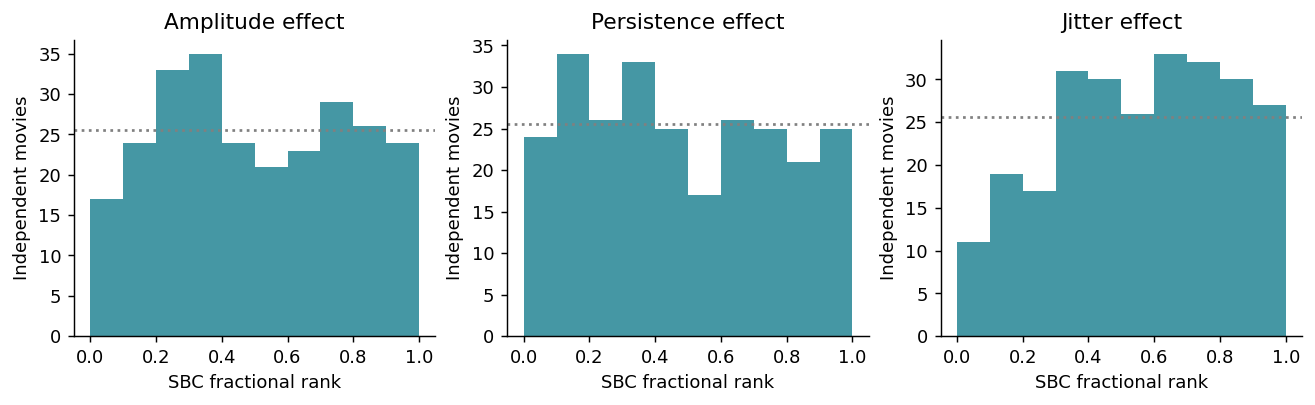

In [3]:
if calibration:
    fig, axes = plt.subplots(1, 3, figsize=(10, 3), constrained_layout=True)
    records = calibration['records']['neural']
    ranks = np.array([r['rank_fraction'] for r in records])
    for ax, j, label in zip(axes, (3,4,5), ('Amplitude effect', 'Persistence effect', 'Jitter effect')):
        ax.hist(ranks[:, j], bins=np.linspace(0,1,11), color='#167d8d', alpha=.8)
        ax.axhline(len(ranks)/10, color='grey', ls=':')
        ax.set(title=label, xlabel='SBC fractional rank', ylabel='Independent movies')
    show(fig)
else:
    print('SBC plot awaits independent prior-predictive simulations.')

Uniform SBC ranks are a necessary diagnostic, not proof of correctness. The model
may discard information and still calibrate; coverage, width, recovery error, and
predictive adequacy must be considered together. These finite simulation counts
provide Monte Carlo estimates, not exact operating characteristics.

In [4]:
scenario_rows = []
if scenarios:
    for scenario, result in scenarios.items():
        for method, aggregate in result['aggregate'].items():
            n = aggregate['n']
            # Recompute intervals from independent per-movie decisions.
            successes = sum(int(r['any_detected']) for r in result[method])
            low, high = wilson_interval(successes, n)
            scenario_rows.append({'scenario': scenario, 'method': method,
                                  'same_training_design': result['in_domain'], 'datasets': n,
                                  'any_direction_detected': successes/n,
                                  'Wilson_low': low, 'Wilson_high': high,
                                  'amplitude_detection': aggregate['detection_rate'][0],
                                  'persistence_detection': aggregate['detection_rate'][1],
                                  'jitter_detection': aggregate['detection_rate'][2]})
    display(pd.DataFrame(scenario_rows).round(3))
else:
    print('Scenario replicates have not been generated.')

,scenario,method,same_training_design,datasets,any_direction_detected,Wilson_low,Wilson_high,amplitude_detection,persistence_detection,jitter_detection
0,null,neural,True,32,0.000,0.000,0.107,0.000,0.000,0.000
1,null,abc,True,32,0.000,0.000,0.107,0.000,0.000,0.000
2,slowdown,neural,True,32,1.000,0.893,1.000,1.000,0.000,0.000
3,slowdown,abc,True,32,0.656,0.483,0.796,0.656,0.000,0.000
4,decorrelation,neural,True,32,0.531,0.364,0.691,0.000,0.531,0.000
5,decorrelation,abc,True,32,0.000,0.000,0.107,0.000,0.000,0.000
6,jitter,neural,True,32,1.000,0.893,1.000,0.000,0.000,1.000
7,jitter,abc,True,32,0.000,0.000,0.107,0.000,0.000,0.000
8,combined,neural,True,32,1.000,0.893,1.000,1.000,0.094,1.000
9,combined,abc,True,32,0.375,0.229,0.547,0.344,0.000,0.062


In [5]:
if ssm_cases:
    rows = []
    for scenario, result in ssm_cases.items():
        d = result['diagnostics']
        rows.append({'scenario': scenario, 'Rhat_max': d['max_rhat'],
                     'ESS_bulk_min': d['min_ess_bulk'], 'ESS_tail_min': d['min_ess_tail'],
                     'sampling_pass': d['converged'],
                     'amplitude_detected': result['detected'][0],
                     'persistence_detected': result['detected'][1],
                     'jitter_detected': result['detected'][2]})
    display(pd.DataFrame(rows).round(3))
    print('These are representative fits. Repeated-dataset operating characteristics are reported separately below.')
else:
    print('State-space example fits are not available yet.')

,scenario,Rhat_max,ESS_bulk_min,ESS_tail_min,sampling_pass,amplitude_detected,persistence_detected,jitter_detected
0,null,1.007,802.689,1074.623,True,False,False,False
1,slowdown,1.009,788.154,945.588,True,True,False,False
2,decorrelation,1.007,856.395,1089.296,True,False,True,False
3,jitter,1.006,801.934,1156.247,True,False,False,True
4,combined,1.003,1674.797,2326.366,True,True,True,True
5,weak,1.006,801.967,922.811,True,False,False,False
6,spontaneous_null,1.006,921.341,1278.530,True,False,False,False
7,mechanical_null,1.005,972.483,1274.817,True,False,False,False
8,noisy_null,1.008,718.798,760.510,True,False,False,False
9,fine_step_combined,1.007,543.640,811.312,True,True,True,True


These are representative fits. Repeated-dataset operating characteristics are reported separately below.


In [6]:
repeated_rows = []
if ssm_repeated:
    for scenario, checked in ssm_repeated.items():
        aggregate = checked.get('aggregate', {})
        attempted = checked.get('n_attempted', len(checked.get('records', [])))
        passed = checked.get('n_passed', aggregate.get('n', 0))
        failed = checked.get('n_failed', attempted - passed)
        bounds = checked.get('any_detection_unresolved_bounds', [np.nan, np.nan])
        wilson = aggregate.get('any_detection_wilson', [np.nan, np.nan])
        repeated_rows.append({'scenario': scenario, 'attempted': attempted, 'passed': passed,
            'failed_or_unresolved': failed,
            'any_detection_among_passed': aggregate.get('any_detection_rate', np.nan),
            'Wilson_low_among_passed': wilson[0], 'Wilson_high_among_passed': wilson[1],
            'overall_unresolved_lower': bounds[0], 'overall_unresolved_upper': bounds[1],
            'amplitude_detection_among_passed': aggregate.get('detection_rate', [np.nan]*3)[0],
            'persistence_detection_among_passed': aggregate.get('detection_rate', [np.nan]*3)[1],
            'jitter_detection_among_passed': aggregate.get('detection_rate', [np.nan]*3)[2]})
    display(pd.DataFrame(repeated_rows).round(3))
    print('Rates condition on sampling success. Counts and unresolved-outcome bounds preserve failed fits in the assessment.')
    print('Stress-case detections are exploratory model-misspecification results; convergence does not validate the movement model.')
else:
    print('Repeated state-space scenarios have not completed; do not infer rates from the representative-fit table.')

,scenario,attempted,passed,failed_or_unresolved,any_detection_among_passed,Wilson_low_among_passed,Wilson_high_among_passed,overall_unresolved_lower,overall_unresolved_upper,amplitude_detection_among_passed,persistence_detection_among_passed,jitter_detection_among_passed
0,null,32,32,0,0.000,0.000,0.107,0.000,0.000,0.0,0.000,0.0
1,combined,32,32,0,1.000,0.893,1.000,1.000,1.000,1.0,0.594,1.0
2,spontaneous_null,8,8,0,0.000,0.000,0.324,0.000,0.000,0.0,0.000,0.0
3,mechanical_null,8,8,0,0.125,0.022,0.471,0.125,0.125,0.0,0.125,0.0


Rates condition on sampling success. Counts and unresolved-outcome bounds preserve failed fits in the assessment.
Stress-case detections are exploratory model-misspecification results; convergence does not validate the movement model.


In [7]:
reference = read_json('reference_validation.json')
reference_rows = []
if reference:
    for scenario, result in reference.items():
        for method, aggregate in result['aggregate'].items():
            interval = aggregate['any_detection_wilson']
            reference_rows.append({'independent_generator_case': scenario, 'method': method,
                'attempted': aggregate['n'], 'passed': np.nan, 'failed': np.nan,
                'any_detection': aggregate['any_detection_rate'],
                'Wilson_low': interval[0], 'Wilson_high': interval[1]})
        checked = result.get('state_space_checked')
        if checked:
            aggregate = checked['aggregate']
            interval = aggregate.get('any_detection_wilson', [np.nan, np.nan])
            reference_rows.append({'independent_generator_case': scenario,
                'method': 'state_space_passed_only', 'attempted': checked['n_attempted'],
                'passed': checked['n_passed'], 'failed': checked['n_failed'],
                'any_detection': aggregate.get('any_detection_rate', np.nan),
                'Wilson_low': interval[0], 'Wilson_high': interval[1]})
    display(pd.DataFrame(reference_rows).round(3))
    print('Sampling-pass counts apply only to MCMC; they are not applicable to ABC/neural draws.')
    print('The independent source ABM uses different polarity/Euler dynamics and initialization. These are raw transfer diagnostics, not accepted guarded classifications.')
else:
    print('Independent source-ABM reference validation is not available yet.')

,independent_generator_case,method,attempted,passed,failed,any_detection,Wilson_low,Wilson_high
0,reference_null,neural,16,NaN,NaN,0.000,0.000,0.194
1,reference_null,abc,16,NaN,NaN,0.000,0.000,0.194
2,reference_null,state_space_passed_only,4,4.0,0.0,0.000,0.000,0.490
3,reference_combined,neural,16,NaN,NaN,1.000,0.806,1.000
4,reference_combined,abc,16,NaN,NaN,0.125,0.035,0.360
5,reference_combined,state_space_passed_only,4,4.0,0.0,1.000,0.510,1.000
6,reference_mechanics,neural,16,NaN,NaN,0.062,0.011,0.283
7,reference_mechanics,abc,16,NaN,NaN,0.000,0.000,0.194
8,reference_mechanics,state_space_passed_only,4,4.0,0.0,0.000,0.000,0.490


Sampling-pass counts apply only to MCMC; they are not applicable to ABC/neural draws.
The independent source ABM uses different polarity/Euler dynamics and initialization. These are raw transfer diagnostics, not accepted guarded classifications.


**Read stress tests as model criticism.** The baseline bank does not train over
spontaneous within-cell changes, adhesion, altered localization error, moving
targets, or fine-step discretization. These deliberate departures test whether
conclusions fail under plausible alternatives. In the noise stress, state-space
inference is told the altered observation-error value whereas the frozen neural
posterior retains its original training protocol; it is not a fully matched comparison.

Mechanical confinement can change effective movement without changing the intrinsic
OU coefficients. An inferred near-target effect in that scenario does not establish
active target sensing. The framework must be expanded before making that claim.

In [8]:
ppc_rows = []
for scenario in ('null', 'combined', 'mechanical_null'):
    ppc = read_json(f'examples/{scenario}_ppc.json')
    if ppc:
        for method, result in ppc.items():
            ppc_rows.append({'scenario': scenario, 'method': method,
                             'fraction_summaries_outside90': result['fraction_features_outside90']})
if ppc_rows:
    display(pd.DataFrame(ppc_rows).round(3))
    print('Summary discrepancies are correlated and reused for SBI fitting; this is not an independent omnibus test.')
else:
    print('Posterior predictive checks await the ppc stage.')

,scenario,method,fraction_summaries_outside90
0,null,neural,0.146
1,null,state_space,0.171
2,combined,neural,0.037
3,combined,state_space,0.037
4,mechanical_null,neural,0.024
5,mechanical_null,state_space,0.037


Summary discrepancies are correlated and reused for SBI fitting; this is not an independent omnibus test.


A useful next decision follows the observed failures:

1. Require adequate within-cell near/far exposure and calibrated observation error.
2. Use independent replication to establish which effects and magnitudes are recoverable.
3. Fit or marginalize mechanical/spontaneous mechanisms when stress tests expose confounding.
4. Validate a revised model on new simulations rather than repeatedly tuning to the same test set.
5. Only then apply the frozen protocol to experimental trajectories.

Synthetic recovery establishes what the inference can recover **under a stated model**;
it cannot answer whether real killer cells change their migration around targets.
The related [NK–target interaction study](https://www.nature.com/articles/s41598-021-94458-0)
motivates target-independent controls and separate checks on directional interactions.